# ICS 3202: Artificial Intelligence, Semester Project Deliverable 2 (CAT 2)
## Predicting Probabilistic Food Price Ranges in Kenya Using Cross-Market Data

**Base model:** Quantile Gradient Boosting (`QuantileGBM_Base.ipynb`)  
**Group:** 191335 - Waweru Collins Wambugu , 190525 - Sinai Mattah Msereke   


---

### The problem
Maize and beans prices in Kenya move a lot. Droughts, transport costs and supply problems in one region can push prices up within a few months.

Most forecasting models give a single number, such as "maize will cost KES 34.50 next month". That looks precise, but it hides the risk. If a drought pushes the real price to KES 45.00, a small trader working on thin margins can lose money they had planned around.

Our model predicts a price range instead:
* **10th percentile ($q=0.10$):** a low estimate.
* **50th percentile ($q=0.50$):** the most likely price.
* **90th percentile ($q=0.90$):** a high estimate, for price spikes and lean seasons.

The low and high values together form an **80% prediction interval**, so the real price should fall inside it about 80% of the time. The main model is Quantile Gradient Boosting (`HistGradientBoostingRegressor`). We limit tree depth and add an L2 penalty to reduce overfitting.

### Why the model predicts the monthly change
Decision trees cannot predict values outside the range they saw in training, so a model that predicts the raw price struggles once prices move into a higher range. Our base model predicts the change from last month ($\Delta P_t = P_t - P_{t-1}$) and then adds last month's price back to each forecast.

---

### Contents
1. Section A: Setup and data loading
2. Section B: Data cleaning (CAT 2 Question 2)
3. Section C: Exploratory data analysis, 4 observations (CAT 2 Question 2)
4. Section D: Feature engineering
5. Section E: Base model and walk-forward validation (CAT 2 Question 3)
6. Section F: Validation roadmap (CAT 2 Question 4)

---
## Section A: Setup and data loading

This section imports the Python libraries and loads the two WFP files. The loader looks in the usual places (Colab's `/content/`, a local `./uploads/` folder and the current folder), so the notebook runs in Colab or on a local machine without any path changes.

In [1]:
# 1. Core library imports
import sys
import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn models and metrics
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import QuantileRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Configure visual styling for clear figures
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

print("Environment setup successful. Python version:", sys.version.split()[0])

Environment setup successful. Python version: 3.13.18


In [2]:
# 2. Dynamic Dataset Path Resolver
def locate_file(filename, search_dirs=None):
    '''Locates a dataset file across multiple environment paths.'''
    if search_dirs is None:
        search_dirs = [
            '.',
            './uploads',
            '/home/user/uploads',
            '/content',
            '/content/drive/MyDrive',
            '../data',
            './data'
        ]
    for d in search_dirs:
        p = os.path.join(d, filename)
        if os.path.exists(p):
            return os.path.abspath(p)
    return None

prices_path = locate_file('wfp_food_prices_ken.csv')
markets_path = locate_file('wfp_markets_ken.csv')

print("Located prices file :", prices_path)
print("Located markets file:", markets_path)

if prices_path is None or markets_path is None:
    raise FileNotFoundError("Please upload 'wfp_food_prices_ken.csv' and 'wfp_markets_ken.csv' to the workspace or Colab environment.")

# Load raw datasets
df_raw_prices = pd.read_csv(prices_path, low_memory=False)
df_raw_markets = pd.read_csv(markets_path)

print(f"\nRaw WFP Prices Loaded : {df_raw_prices.shape[0]:,} rows, {df_raw_prices.shape[1]} columns")
print(f"Raw WFP Markets Loaded: {df_raw_markets.shape[0]:,} markets, {df_raw_markets.shape[1]} columns")

Located prices file : /content/wfp_food_prices_ken.csv
Located markets file: /content/wfp_markets_ken.csv

Raw WFP Prices Loaded : 28,463 rows, 16 columns
Raw WFP Markets Loaded: 280 markets, 7 columns


In [3]:
# 3. Raw Inspection & Structural Audit
print("=== WFP Food Prices Schema & Null Audit ===")
display_info = pd.DataFrame({
    'Data Type': df_raw_prices.dtypes,
    'Null Count': df_raw_prices.isnull().sum(),
    'Null Pct (%)': (df_raw_prices.isnull().sum() / len(df_raw_prices) * 100).round(2),
    'Sample Value': df_raw_prices.iloc[0].values
})
print(display_info)

print(f"\nDate Range: {df_raw_prices['date'].min()} to {df_raw_prices['date'].max()}")
print(f"Unique Commodities Recorded: {df_raw_prices['commodity'].nunique()}")
print(f"Unique Markets Recorded: {df_raw_prices['market'].nunique()}")
print(f"Price Types: {df_raw_prices['pricetype'].value_counts().to_dict()}")

=== WFP Food Prices Schema & Null Audit ===
             Data Type  Null Count  Null Pct (%)        Sample Value
date            object           0          0.00          2006-01-15
admin1          object          68          0.24               Coast
admin2          object          68          0.24             Mombasa
market          object           0          0.00             Mombasa
market_id        int64           0          0.00                 191
latitude       float64          68          0.24               -4.05
longitude      float64          68          0.24               39.67
category        object           0          0.00  cereals and tubers
commodity       object           0          0.00               Maize
commodity_id     int64           0          0.00                  51
unit            object           0          0.00                  KG
priceflag       object           0          0.00              actual
pricetype       object           0          0.00           

---
## Section B: Data cleaning (CAT 2 Question 2)

The raw WFP file covers 2006 to 2026 and holds many products and markets. We turn it into a modelling table in six steps, and each step has a reason.

1. **Commodities.** We keep maize and beans. WFP changed its labels over the years (`Maize (white)`, `Maize (white, dry)`, `Maize`; `Beans (dry)`, `Beans (rosecoco)`, `Beans (yellow)`), so we group them into `Maize` and `Beans`. We drop `Maize flour` and `Maize flour (white)`, because milling, packaging and brand markups mean flour prices don't follow the grain market closely.
2. **Units.** Wholesale grain in Kenya is usually sold in 90 kg bags, while retail prices are quoted per kg. Mixing the two would make some prices look 90 times higher than others, so we convert everything to KES per kg (bag prices divided by 90).
3. **Price type.** In the five main grain markets (Eldoret, Nakuru, Nairobi, Kisumu, Mombasa), over 98% of records are wholesale. Dry-land counties such as Kitui and Mandera are mostly recorded at retail, for food-security monitoring. We model wholesale prices.
4. **Price flag.** WFP marks some records as `aggregate` (an average from several sources) instead of `actual`. We keep them so the monthly series has fewer gaps. We did not test whether this choice changes the results.
5. **Duplicates.** If a market has more than one record for the same commodity in the same month, we take the monthly mean.
6. **Monthly grid.** Forecasting needs one row per month. We rebuild each market's series from 2008 to 2021 and fill missing months by drawing a straight line between the months on either side (linear interpolation). The next cell reports how many values this affects.

In [4]:
# 1. Commodity Filtering & Harmonization
# Strictly exclude processed flour
is_flour = df_raw_prices['commodity'].str.contains('flour', case=False, na=False)
is_maize_or_beans = df_raw_prices['commodity'].str.contains('Maize|Beans', case=False, na=False)
df_filtered = df_raw_prices[is_maize_or_beans & (~is_flour)].copy()

# Standardize commodity labels
def harmonize_commodity(commodity_name):
    c = str(commodity_name).lower()
    if 'maize' in c:
        return 'Maize'
    elif 'beans' in c:
        return 'Beans'
    return 'Other'

df_filtered['commodity_group'] = df_filtered['commodity'].apply(harmonize_commodity)
print("Harmonized Commodity Counts:")
print(df_filtered['commodity_group'].value_counts())

# 2. Unit Normalization to KES per kg
def normalize_to_kg(row):
    unit = str(row['unit']).strip().upper()
    price = row['price']
    if unit == 'KG':
        return price
    elif unit == '90 KG':
        return price / 90.0
    elif unit == '50 KG':
        return price / 50.0
    else:
        return np.nan

df_filtered['price_per_kg'] = df_filtered.apply(normalize_to_kg, axis=1)
df_filtered = df_filtered.dropna(subset=['price_per_kg']).copy()

# Convert date column
df_filtered['date'] = pd.to_datetime(df_filtered['date'])
df_filtered['year_month'] = df_filtered['date'].dt.to_period('M')

print(f"\nRows after commodity filtering & unit normalization: {len(df_filtered):,}")
print("Price per kg summary (KES/kg):")
print(df_filtered.groupby(['commodity_group', 'pricetype'])['price_per_kg'].describe()[['count', 'mean', 'std', 'min', '50%', 'max']].round(2))

Harmonized Commodity Counts:
commodity_group
Beans    4336
Maize    4319
Name: count, dtype: int64

Rows after commodity filtering & unit normalization: 8,655
Price per kg summary (KES/kg):
                            count    mean    std    min     50%     max
commodity_group pricetype                                              
Beans           Retail     1804.0  131.24  38.51  23.00  126.84  270.00
                Wholesale  2532.0   82.55  34.05  12.60   75.60  220.00
Maize           Retail     2303.0   59.91  22.48   6.00   56.25  152.00
                Wholesale  2016.0   32.62  13.63   8.91   30.86   90.42


In [5]:
# 3. Market Selection & Monthly Grid Construction
# Focus on the 5 Core National Commercial Wholesale Hubs
benchmark_markets = [
    'Eldoret town (Uasin Gishu)', # North Rift Production Grain Basket
    'Nairobi',                    # Primary National Consumption Terminal Market
    'Kisumu',                     # Western Hub / Lake Victoria Trade
    'Mombasa',                    # Coastal Consumption Hub & Port Entry
    'Nakuru'                      # Central Rift Transit & Agricultural Hub
]

# Filter wholesale records for benchmark hubs
df_benchmark = df_filtered[
    (df_filtered['pricetype'] == 'Wholesale') &
    (df_filtered['market'].isin(benchmark_markets))
].copy()

# Deduplicate by taking the monthly mean per market and commodity
df_monthly_clean = df_benchmark.groupby(
    ['year_month', 'market', 'commodity_group']
)['price_per_kg'].mean().reset_index()

# Construct a continuous monthly index from 2008-01 to 2021-12 (168 months)
full_monthly_index = pd.period_range(start='2008-01', end='2021-12', freq='M')

# Track missing values before interpolation to quantify data imputation
imputation_audit = {}

balanced_series_list = []
for comm in ['Maize', 'Beans']:
    comm_df = df_monthly_clean[df_monthly_clean['commodity_group'] == comm]
    pvt = comm_df.pivot(index='year_month', columns='market', values='price_per_kg')
    pvt_reindexed = pvt[benchmark_markets].reindex(full_monthly_index)

    # Audit missingness
    missing_overall = pvt_reindexed.isnull().sum()
    missing_test = pvt_reindexed.loc['2017-01':'2021-12'].isnull().sum()
    imputation_audit[comm] = {
        'overall_missing': missing_overall,
        'test_missing': missing_test
    }

    # Linearly interpolate isolated gaps
    pvt_interpolated = pvt_reindexed.interpolate(method='linear')

    for mkt in benchmark_markets:
        sub = pd.DataFrame({
            'date': full_monthly_index.to_timestamp(),
            'year_month': full_monthly_index,
            'commodity': comm,
            'market': mkt,
            'price_per_kg': pvt_interpolated[mkt].values
        })
        balanced_series_list.append(sub)

df_modelling_base = pd.concat(balanced_series_list, ignore_index=True)
print(f"Final Balanced Modelling Dataset Shape: {df_modelling_base.shape[0]} rows (5 markets x 2 commodities x 168 months)")

# Print exact interpolation audit for Maize
total_maize_cells = len(full_monthly_index) * len(benchmark_markets)
missing_maize_overall = imputation_audit['Maize']['overall_missing'].sum()
test_maize_cells = 60 * len(benchmark_markets)
missing_maize_test = imputation_audit['Maize']['test_missing'].sum()

print("\n=== Missing Values Filled by Linear Interpolation (Maize) ===")
print(f"Overall Period (2008–2021): {missing_maize_overall} / {total_maize_cells} values ({missing_maize_overall/total_maize_cells*100:.1f}%)")
print("Missing by market overall:\n", imputation_audit['Maize']['overall_missing'])
print(f"\nTest Period (2017–2021): {missing_maize_test} / {test_maize_cells} values ({missing_maize_test/test_maize_cells*100:.1f}%)")
print("Missing by market in test period:\n", imputation_audit['Maize']['test_missing'])

Final Balanced Modelling Dataset Shape: 1680 rows (5 markets x 2 commodities x 168 months)

=== Missing Values Filled by Linear Interpolation (Maize) ===
Overall Period (2008–2021): 51 / 840 values (6.1%)
Missing by market overall:
 market
Eldoret town (Uasin Gishu)     2
Nairobi                        4
Kisumu                        25
Mombasa                       13
Nakuru                         7
dtype: int64

Test Period (2017–2021): 45 / 300 values (15.0%)
Missing by market in test period:
 market
Eldoret town (Uasin Gishu)     2
Nairobi                        4
Kisumu                        24
Mombasa                       12
Nakuru                         3
dtype: int64


### Limitation: missing months and interpolation
Some monthly records were missing from the raw WFP data, and we filled them by linear interpolation.
* **Whole period (2008 to 2021):** 51 of 840 maize values (**6.1%**) across the five markets were filled this way.
* **Test years (2017 to 2021):** 45 of 300 values (**15.0%**) were filled. The gaps sit mostly in two markets. Kisumu has 24 missing months (40.0% of the test period) and Mombasa has 12 (20.0%). Nairobi has 4 (6.7%) and Eldoret has 2 (3.3%). The dataset does not say why the gaps occurred.
* **Effect on the results:** Interpolation smooths out short-term price swings, so some test targets, especially for Kisumu and Mombasa, are estimates and not recorded prices. Keep this in mind when reading the results for those markets.

---
## Section C: Exploratory data analysis (CAT 2 Question 2)

We make four observations from the cleaned data. Each one has a plot, and the numbers below come from the outputs of the code cells in this section.

**Observation 1: Prices spike during droughts.**
* 2008: post-election violence and rising global food prices pushed prices up (background context, not tested here).
* 2011: during the Horn of Africa drought, wholesale maize peaked at **KES 53.18/kg**.
* 2017: during the national drought, it peaked at **KES 58.58/kg**, the highest value in our 2008 to 2021 data.

**Observation 2: Prices follow a yearly cycle.** Maize is cheapest in January, at an average of **KES 28.59/kg**, after the harvest. It is dearest in June, at **KES 33.52/kg**, when stocks run low before the next harvest. That is a **17.3%** swing.

**Observation 3 (RQ5): Distance matters for monthly changes, not for price levels.** We correlated the five markets in pairs (10 pairs) and compared two versions.
* **Price levels:** no clear link with distance (rank correlation $-0.164$, p-value $0.6515$). For example, Eldoret and Kisumu are 90.7 km apart and correlate at **0.802**, while Nairobi and Mombasa are 441.7 km apart and correlate at **0.917**.
* **Monthly price changes:** correlation generally falls as distance rises (rank correlation $-0.818$, p-value $0.0038$). The four pairs within 150 km score between **0.565** and **0.630**. The lowest score is **0.451**, for Kisumu and Mombasa (701.2 km apart). It is a general downward trend and not a strict rule: Nairobi and Mombasa (441.7 km) score 0.553, higher than Eldoret and Nairobi (263.4 km) at 0.492.
* **Why the two versions differ:** maize prices in all five markets trend upward over the years. That shared climb keeps level correlations high for every pair and hides the distance effect. Using monthly changes removes the climb.
* **Limits:** Kisumu and Mombasa have the most interpolated months, which can distort monthly changes. There are also only 10 pairs, from 5 markets.

**Observation 4: Regional price gaps differ a lot between dry-land markets.** We compared Nairobi wholesale maize with retail maize in four dry-land markets: Kitui, Mandera, Lodwar (Turkana) and Marsabit. These have the longest retail maize records in the dataset (from 2006). Each market has a slightly different number of months in common with Nairobi (168 to 177, all from 2006-01 to 2020-11).

| Market | Overlap (months) | Average gap | Largest gap (month) | Smallest gap | Months retail was below Nairobi |
|---|---|---|---|---|---|
| Kitui | 177 | KES 1.70/kg (4.7%) | KES 11.36/kg (2018-10) | KES -14.16/kg | 27.1% |
| Mandera | 176 | KES 27.66/kg (97.3%) | KES 50.83/kg (2020-09) | KES 4.30/kg | 0.0% |
| Lodwar (Turkana) | 174 | KES 31.92/kg (112.4%) | KES 55.74/kg (2013-04) | KES 7.30/kg | 0.0% |
| Marsabit | 168 | KES 12.53/kg (45.4%) | KES 27.93/kg (2011-09) | KES -5.76/kg | 2.4% |

* The four markets do not behave alike. Mandera and Lodwar sit well above Nairobi wholesale in every month. Marsabit is above it in nearly every month. Kitui's average gap is small, and its retail price was below Nairobi wholesale in about 27% of months. The data does not say why Kitui differs.
* The largest gaps fall in different years (2018, 2020, 2013 and 2011), so we cannot tie them to one drought.
* We call this a regional price gap and not a retail margin, because it mixes distance and transport costs with the difference between wholesale and retail pricing.

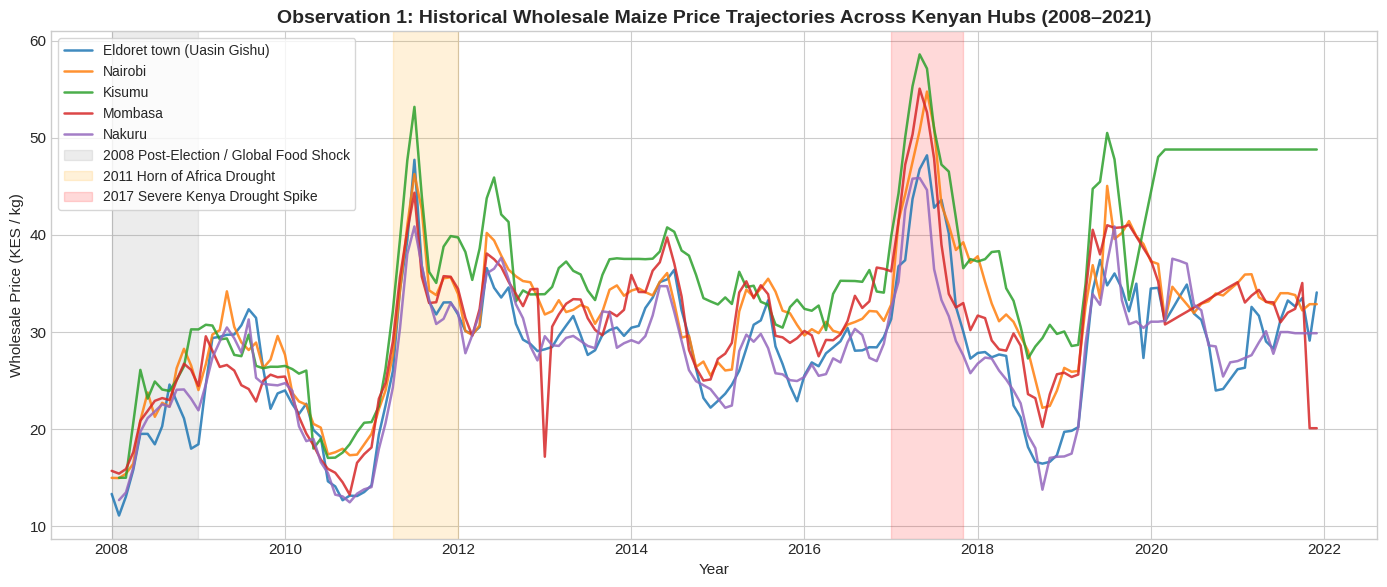

Key Numerical Takeaways (Observation 1):
2011 Peak Maize Price : KES 53.18/kg
2017 Drought Peak Price: KES 58.58/kg


In [6]:
# === Observation 1: Macro Price Trajectory & Historical Crisis Shocks ===
fig, ax = plt.subplots(figsize=(14, 6))

maize_pvt = df_modelling_base[df_modelling_base['commodity'] == 'Maize'].pivot(
    index='date', columns='market', values='price_per_kg'
)

for mkt in benchmark_markets:
    ax.plot(maize_pvt.index, maize_pvt[mkt], label=mkt, linewidth=1.8, alpha=0.85)

# Highlight macro shock windows
ax.axvspan(pd.to_datetime('2008-01-01'), pd.to_datetime('2008-12-31'), color='gray', alpha=0.15, label='2008 Post-Election / Global Food Shock')
ax.axvspan(pd.to_datetime('2011-04-01'), pd.to_datetime('2011-12-31'), color='orange', alpha=0.15, label='2011 Horn of Africa Drought')
ax.axvspan(pd.to_datetime('2017-01-01'), pd.to_datetime('2017-10-31'), color='red', alpha=0.15, label='2017 Severe Kenya Drought Spike')

ax.set_title("Observation 1: Historical Wholesale Maize Price Trajectories Across Kenyan Hubs (2008–2021)", fontsize=14, fontweight='bold')
ax.set_xlabel("Year")
ax.set_ylabel("Wholesale Price (KES / kg)")
ax.legend(loc='upper left', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

print("Key Numerical Takeaways (Observation 1):")
print(f"2011 Peak Maize Price : KES {maize_pvt.loc['2011-01-01':'2011-12-31'].max().max():.2f}/kg")
print(f"2017 Drought Peak Price: KES {maize_pvt.loc['2017-01-01':'2017-12-31'].max().max():.2f}/kg")

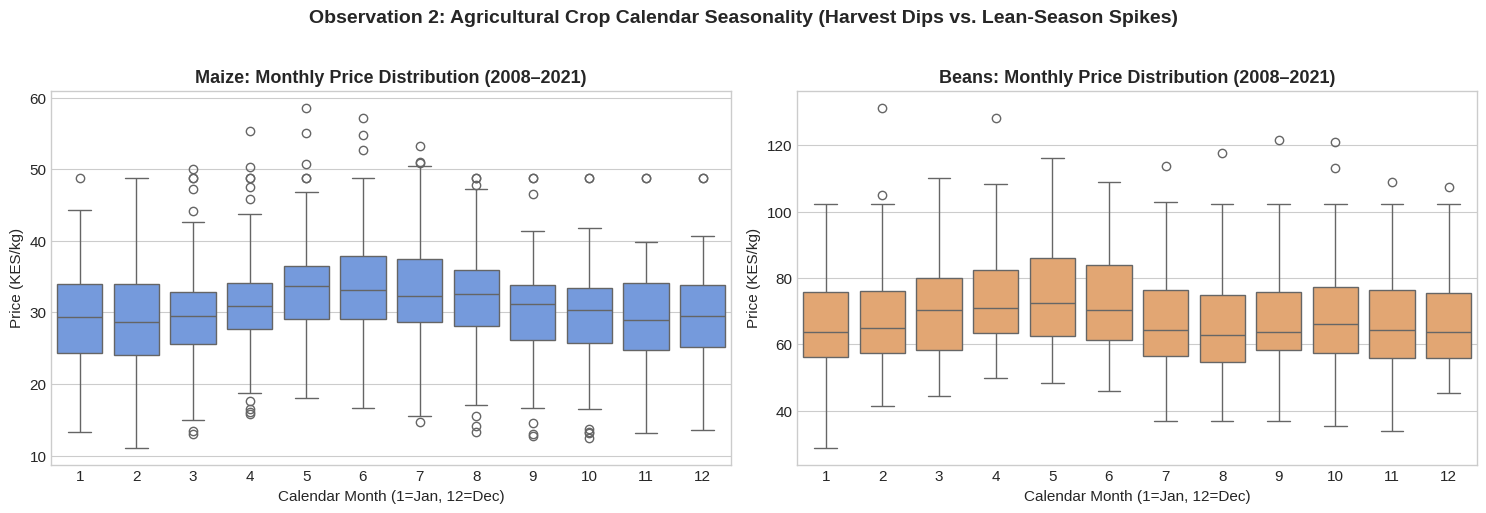

Maize Annual Lowest Month : Month 1 (Jan) with mean KES 28.59/kg
Maize Annual Peak Month   : Month 6 (Jun) with mean KES 33.52/kg
Average Annual Seasonal Price Swing: 17.3%


In [7]:
# === Observation 2: Seasonality and the Crop Harvest Calendar ===
df_modelling_base['month'] = df_modelling_base['date'].dt.month

seasonal_summary = df_modelling_base.groupby(['commodity', 'month'])['price_per_kg'].agg(
    ['mean', 'std', 'min', 'max']
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Maize Seasonality
sns.boxplot(
    data=df_modelling_base[df_modelling_base['commodity'] == 'Maize'],
    x='month', y='price_per_kg', ax=axes[0], color='cornflowerblue'
)
axes[0].set_title("Maize: Monthly Price Distribution (2008–2021)", fontweight='bold')
axes[0].set_xlabel("Calendar Month (1=Jan, 12=Dec)")
axes[0].set_ylabel("Price (KES/kg)")

# Beans Seasonality
sns.boxplot(
    data=df_modelling_base[df_modelling_base['commodity'] == 'Beans'],
    x='month', y='price_per_kg', ax=axes[1], color='sandybrown'
)
axes[1].set_title("Beans: Monthly Price Distribution (2008–2021)", fontweight='bold')
axes[1].set_xlabel("Calendar Month (1=Jan, 12=Dec)")
axes[1].set_ylabel("Price (KES/kg)")

plt.suptitle("Observation 2: Agricultural Crop Calendar Seasonality (Harvest Dips vs. Lean-Season Spikes)", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Quantitative Seasonal Swing
month_names = {1:'Jan', 2:'Feb', 3:'Mar', 4:'Apr', 5:'May', 6:'Jun', 7:'Jul', 8:'Aug', 9:'Sep', 10:'Oct', 11:'Nov', 12:'Dec'}
maize_seasonal = seasonal_summary[seasonal_summary['commodity'] == 'Maize']
min_month_row = maize_seasonal.loc[maize_seasonal['mean'].idxmin()]
max_month_row = maize_seasonal.loc[maize_seasonal['mean'].idxmax()]
swing_pct = ((max_month_row['mean'] - min_month_row['mean']) / min_month_row['mean']) * 100

print(f"Maize Annual Lowest Month : Month {int(min_month_row['month'])} ({month_names[int(min_month_row['month'])]}) with mean KES {min_month_row['mean']:.2f}/kg")
print(f"Maize Annual Peak Month   : Month {int(max_month_row['month'])} ({month_names[int(max_month_row['month'])]}) with mean KES {max_month_row['mean']:.2f}/kg")
print(f"Average Annual Seasonal Price Swing: {swing_pct:.1f}%")

Loading market coordinates from wfp_markets_ken.csv:
  Matched 'Eldoret town (Uasin Gishu)': lat=0.52, lon=35.28
  Matched 'Nairobi': lat=-1.28, lon=36.82
  Matched 'Kisumu': lat=-0.1, lon=34.75
  Matched 'Mombasa': lat=-4.05, lon=39.67
  Matched 'Nakuru': lat=-0.28, lon=36.07


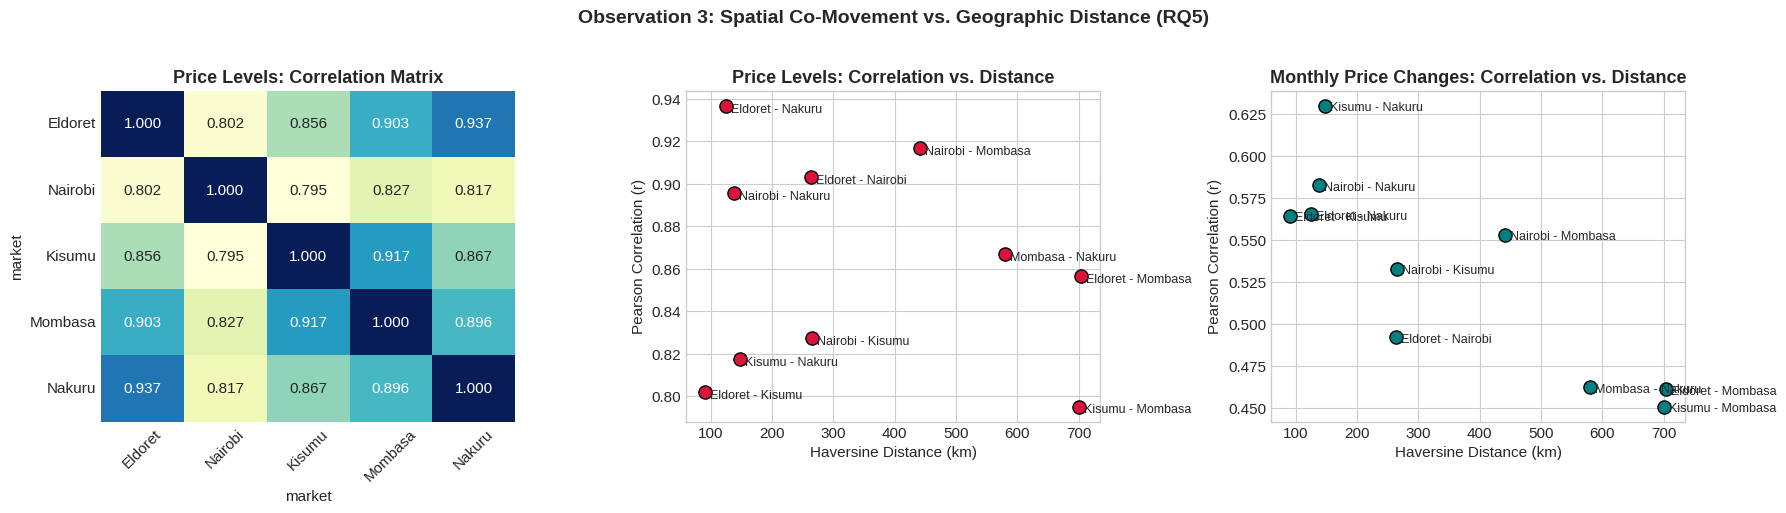

Pairwise Geographic Distance vs Correlation Summary (Price Levels):
      Market Pair  Distance_km  Correlation
 Eldoret - Kisumu         90.7     0.801775
 Eldoret - Nakuru        125.0     0.936618
 Nairobi - Nakuru        139.0     0.895544
  Kisumu - Nakuru        148.1     0.817407
Eldoret - Nairobi        263.4     0.903249
 Nairobi - Kisumu        264.9     0.827253
Nairobi - Mombasa        441.7     0.916775
 Mombasa - Nakuru        579.4     0.866985
 Kisumu - Mombasa        701.2     0.795157
Eldoret - Mombasa        704.4     0.856446

=== Combined Correlation Table (Price Levels vs. Monthly Changes) Sorted by Distance ===
      Market Pair  Distance_km  Level Correlation  Change Correlation
 Eldoret - Kisumu         90.7              0.802               0.565
 Eldoret - Nakuru        125.0              0.937               0.565
 Nairobi - Nakuru        139.0              0.896               0.583
  Kisumu - Nakuru        148.1              0.817               0.630
Eldoret 

In [8]:
# === Observation 3: Spatial Co-Movement vs Geographic Distance (RQ5) ===
from scipy import stats

# 1. Haversine distance formula
def compute_haversine(lat1, lon1, lat2, lon2):
    R = 6371.0 # Earth radius in km
    dlat = math.radians(lat2 - lat1)
    dlon = math.radians(lon2 - lon1)
    a = math.sin(dlat / 2)**2 + math.cos(math.radians(lat1)) * math.cos(math.radians(lat2)) * math.sin(dlon / 2)**2
    c = 2 * math.atan2(math.sqrt(a), math.sqrt(1 - a))
    return R * c

# 2. Extract market coordinates from wfp_markets_ken.csv
mkt_coords = {}
print("Loading market coordinates from wfp_markets_ken.csv:")
for mkt in benchmark_markets:
    match = df_raw_markets[df_raw_markets['market'] == mkt]
    if len(match) > 0:
        row = match.iloc[0]
        mkt_coords[mkt] = (float(row['latitude']), float(row['longitude']))
        print(f"  Matched '{mkt}': lat={row['latitude']}, lon={row['longitude']}")
    else:
        print(f"  Name not matched directly: '{mkt}'. Searching fallback...")
        fuzzy = df_raw_markets[df_raw_markets['market'].str.contains(mkt.split()[0], case=False, na=False)]
        if len(fuzzy) > 0:
            row = fuzzy.iloc[0]
            mkt_coords[mkt] = (float(row['latitude']), float(row['longitude']))
            print(f"  Fixed to '{row['market']}': lat={row['latitude']}, lon={row['longitude']}")
        else:
            print(f"  ERROR: No coordinate match found for '{mkt}'.")

# 3. Distance matrix
dist_df = pd.DataFrame(index=benchmark_markets, columns=benchmark_markets, dtype=float)
for m1 in benchmark_markets:
    for m2 in benchmark_markets:
        dist_df.loc[m1, m2] = round(compute_haversine(mkt_coords[m1][0], mkt_coords[m1][1], mkt_coords[m2][0], mkt_coords[m2][1]), 1)

# 4. Price level correlations and monthly change correlations
maize_corr_level = maize_pvt.corr()
maize_diff = maize_pvt.diff().dropna()
maize_corr_change = maize_diff.corr()

# 5. Assemble pairwise records
pairs = []
for i in range(len(benchmark_markets)):
    for j in range(i + 1, len(benchmark_markets)):
        m1 = benchmark_markets[i]
        m2 = benchmark_markets[j]
        pairs.append({
            'Market Pair': f"{m1.split()[0]} - {m2.split()[0]}",
            'Distance_km': dist_df.loc[m1, m2],
            'Level Correlation': maize_corr_level.loc[m1, m2],
            'Change Correlation': maize_corr_change.loc[m1, m2]
        })

df_dist_corr = pd.DataFrame(pairs).sort_values('Distance_km').reset_index(drop=True)

# 6. Plots: Level correlation heatmap, Level scatter, Change scatter
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Heatmap of level correlations
sns.heatmap(maize_corr_level, annot=True, fmt=".3f", cmap='YlGnBu', ax=axes[0], cbar=False)
axes[0].set_title("Price Levels: Correlation Matrix", fontweight='bold')
axes[0].set_xticklabels([m.split()[0] for m in benchmark_markets], rotation=45)
axes[0].set_yticklabels([m.split()[0] for m in benchmark_markets], rotation=0)

# Scatter of Distance vs. Level Correlation
axes[1].scatter(df_dist_corr['Distance_km'], df_dist_corr['Level Correlation'], color='crimson', s=90, edgecolors='black')
for _, row in df_dist_corr.iterrows():
    axes[1].annotate(row['Market Pair'], (row['Distance_km'] + 8, row['Level Correlation'] - 0.003), fontsize=9)
axes[1].set_title("Price Levels: Correlation vs. Distance", fontweight='bold')
axes[1].set_xlabel("Haversine Distance (km)")
axes[1].set_ylabel("Pearson Correlation (r)")

# Scatter of Distance vs. Change Correlation
axes[2].scatter(df_dist_corr['Distance_km'], df_dist_corr['Change Correlation'], color='teal', s=90, edgecolors='black')
for _, row in df_dist_corr.iterrows():
    axes[2].annotate(row['Market Pair'], (row['Distance_km'] + 8, row['Change Correlation'] - 0.003), fontsize=9)
axes[2].set_title("Monthly Price Changes: Correlation vs. Distance", fontweight='bold')
axes[2].set_xlabel("Haversine Distance (km)")
axes[2].set_ylabel("Pearson Correlation (r)")

plt.suptitle("Observation 3: Spatial Co-Movement vs. Geographic Distance (RQ5)", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# 7. Print tables and Spearman rank correlations
print("Pairwise Geographic Distance vs Correlation Summary (Price Levels):")
print(df_dist_corr[['Market Pair', 'Distance_km', 'Level Correlation']].rename(columns={'Level Correlation': 'Correlation'}).to_string(index=False))

print("\n=== Combined Correlation Table (Price Levels vs. Monthly Changes) Sorted by Distance ===")
print(df_dist_corr[['Market Pair', 'Distance_km', 'Level Correlation', 'Change Correlation']].round(3).to_string(index=False))

# Spearman rank correlation between distance and each correlation type
spearman_level = stats.spearmanr(df_dist_corr['Distance_km'], df_dist_corr['Level Correlation'])
spearman_change = stats.spearmanr(df_dist_corr['Distance_km'], df_dist_corr['Change Correlation'])

print(f"\nSpearman rank correlation (Distance vs. Price Level Correlation): rho = {spearman_level.statistic:.3f}, p-value = {spearman_level.pvalue:.4f}")
print(f"Spearman rank correlation (Distance vs. Monthly Change Correlation): rho = {spearman_change.statistic:.3f}, p-value = {spearman_change.pvalue:.4f}")

Checking exact target market names in df_filtered retail records:
  'Kitui' present: True
  'Mandera' present: True
  'Lodwar (Turkana)' present: True
  'Marsabit' present: True

=== Regional Price Gap Summary (Retail Market vs. Nairobi Wholesale Maize) ===
          Market  Overlap Months Overlap Start Overlap End  Average Gap (KES/kg)  Average Gap (%)  Max Gap (KES/kg)  Gap % in That Month Max Gap Month  Min Gap (KES/kg)  Months Below Nairobi (%)
           Kitui             177       2006-01     2020-11                  1.70              4.7             11.36                 51.2       2018-10            -14.16                      27.1
         Mandera             176       2006-01     2020-11                 27.66             97.3             50.83                153.2       2020-09              4.30                       0.0
Lodwar (Turkana)             174       2006-01     2020-11                 31.92            112.4             55.74                173.9       2013-04       

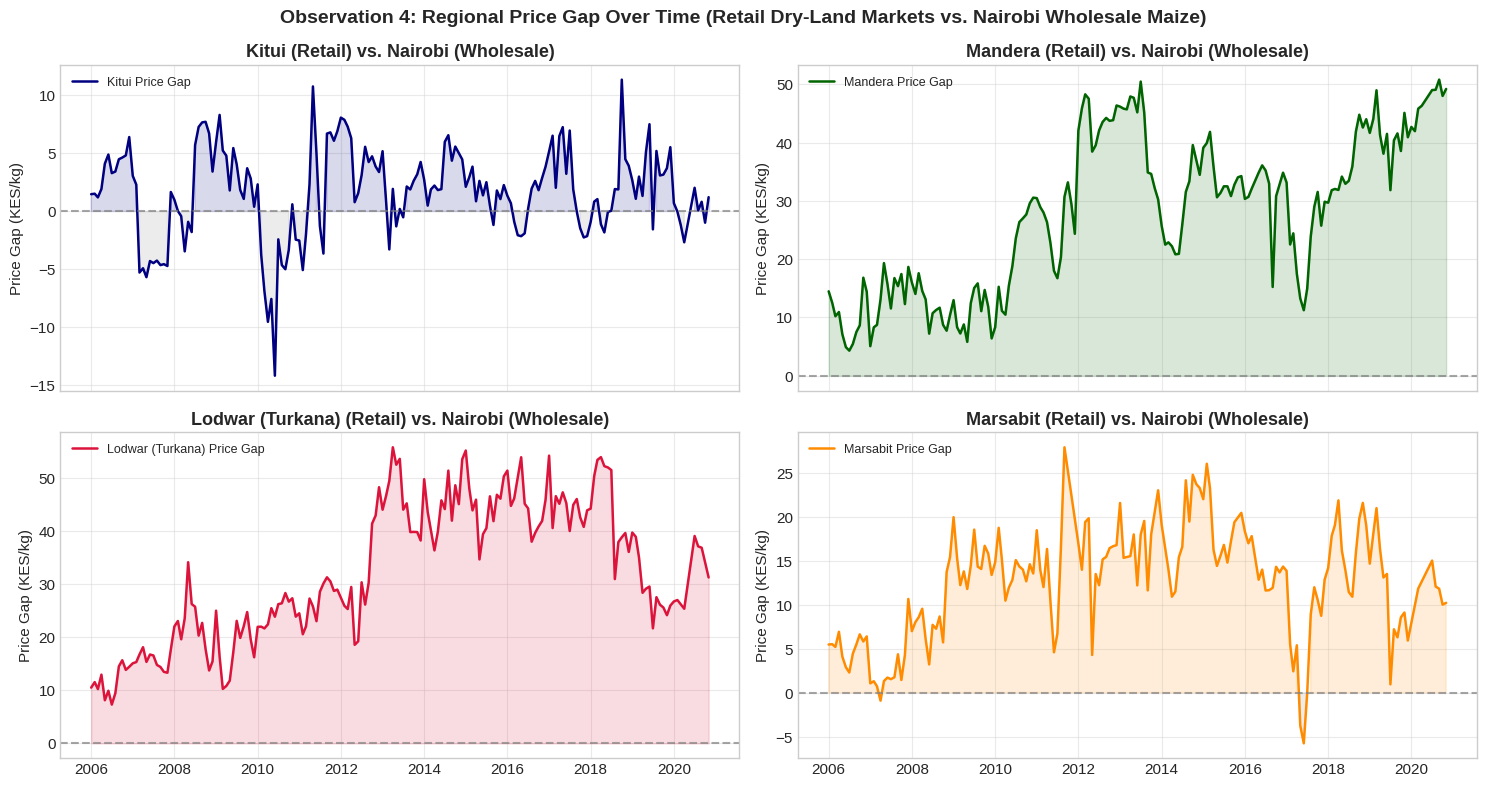

In [9]:
# === Observation 4: Regional Price Gap (Wholesale Nairobi vs. Four Dry-Land Retail Markets) ===
dryland_markets = ['Kitui', 'Mandera', 'Lodwar (Turkana)', 'Marsabit']

# 1. Check exact market names in df_filtered
print("Checking exact target market names in df_filtered retail records:")
available_retail = set(df_filtered[df_filtered['pricetype'] == 'Retail']['market'].unique())
for mkt in dryland_markets:
    print(f"  '{mkt}' present: {mkt in available_retail}")

# Monthly average Nairobi Wholesale Maize
nbi_ws_monthly = df_filtered[
    (df_filtered['market'] == 'Nairobi') &
    (df_filtered['commodity_group'] == 'Maize') &
    (df_filtered['pricetype'] == 'Wholesale')
].groupby('year_month')['price_per_kg'].mean()

# 2. Compare retail maize with Nairobi wholesale maize for overlapping months
gap_records = []
gap_dfs = {}

for mkt in dryland_markets:
    mkt_retail = df_filtered[
        (df_filtered['market'] == mkt) &
        (df_filtered['commodity_group'] == 'Maize') &
        (df_filtered['pricetype'] == 'Retail')
    ].groupby('year_month')['price_per_kg'].mean()

    comp = pd.DataFrame({'Wholesale_Nairobi': nbi_ws_monthly, 'Retail': mkt_retail}).dropna()
    comp['Gap_KES'] = comp['Retail'] - comp['Wholesale_Nairobi']
    comp['Gap_Pct'] = (comp['Gap_KES'] / comp['Wholesale_Nairobi']) * 100.0
    gap_dfs[mkt] = comp

    overlap_count = len(comp)
    start_m = str(comp.index.min())
    end_m = str(comp.index.max())
    mean_gap_kes = comp['Gap_KES'].mean()
    mean_gap_pct = comp['Gap_Pct'].mean()

    max_idx = comp['Gap_KES'].idxmax()
    max_gap_kes = comp.loc[max_idx, 'Gap_KES']
    max_gap_pct = comp.loc[max_idx, 'Gap_Pct']

    gap_records.append({
        'Market': mkt,
        'Overlap Months': overlap_count,
        'Overlap Start': start_m,
        'Overlap End': end_m,
        'Average Gap (KES/kg)': round(mean_gap_kes, 2),
        'Average Gap (%)': round(mean_gap_pct, 1),
        'Max Gap (KES/kg)': round(max_gap_kes, 2),
        'Gap % in That Month': round(max_gap_pct, 1),
        'Max Gap Month': str(max_idx),
        'Min Gap (KES/kg)': round(comp['Gap_KES'].min(), 2),
        'Months Below Nairobi (%)': round((comp['Gap_KES'] < 0).mean() * 100, 1)
    })

df_gap_summary = pd.DataFrame(gap_records)
print("\n=== Regional Price Gap Summary (Retail Market vs. Nairobi Wholesale Maize) ===")
print(df_gap_summary.to_string(index=False))

# 3. Plot the four gaps (four panels)
fig, axes = plt.subplots(2, 2, figsize=(15, 8), sharex=True)
axes = axes.flatten()

colors = ['navy', 'darkgreen', 'crimson', 'darkorange']

for i, mkt in enumerate(dryland_markets):
    ax = axes[i]
    comp = gap_dfs[mkt]
    dates = comp.index.to_timestamp()

    ax.plot(dates, comp['Gap_KES'], label=f'{mkt} Price Gap', color=colors[i], linewidth=1.8)
    ax.axhline(0, color='gray', linestyle='--', alpha=0.7)
    ax.fill_between(dates, 0, comp['Gap_KES'], where=(comp['Gap_KES'] >= 0), color=colors[i], alpha=0.15)
    ax.fill_between(dates, 0, comp['Gap_KES'], where=(comp['Gap_KES'] < 0), color='gray', alpha=0.15)

    ax.set_title(f"{mkt} (Retail) vs. Nairobi (Wholesale)", fontweight='bold')
    ax.set_ylabel("Price Gap (KES/kg)")
    ax.legend(loc='upper left', fontsize=9)
    ax.grid(True, alpha=0.4)

plt.suptitle("Observation 4: Regional Price Gap Over Time (Retail Dry-Land Markets vs. Nairobi Wholesale Maize)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---
## Section D: Feature engineering

The model needs a table of clues for each month. Every clue uses only information available up to the previous month ($t-1$), so the model never sees the answer it is predicting. There are four groups of clues, plus the target.

1. **Price lags.** `price_lag1` (last month), `price_lag2` (two months ago), `price_lag3` (three months ago) and `price_lag12` (the same month last year).
2. **Rolling statistics.** `roll_mean_3` and `roll_std_3` are the 3-month average and spread. `roll_mean_6` and `roll_std_6` are the same over 6 months.
3. **Calendar.** December is followed by January, so the month number alone is misleading. We encode the month as a point on a circle:
   $$\text{month\_sin} = \sin\left(\frac{2\pi \cdot \text{month}}{12}\right), \quad \text{month\_cos} = \cos\left(\frac{2\pi \cdot \text{month}}{12}\right)$$
4. **Neighbouring markets.** For each market $m$, `spatial_neighbor_lag1` is last month's price in the other four markets, weighted by the inverse of distance so that nearer markets count more:
   $$\text{spatial\_neighbor\_lag1}_m = \frac{\sum_{k \neq m} \frac{1}{d(m, k)} P_{k, t-1}}{\sum_{k \neq m} \frac{1}{d(m, k)}}$$
   We also add `eldoret_lag1`, because Eldoret sits in Kenya's main maize-growing region.
5. **Target.** The monthly change, $\Delta P_t = P_t - P_{t-1}$ (`price_change`).

In [10]:
# Feature Engineering Construction Function
def build_feature_table(df_base, dist_matrix):
    feature_dfs = []

    for comm in ['Maize', 'Beans']:
        comm_sub = df_base[df_base['commodity'] == comm]
        pvt = comm_sub.pivot(index='date', columns='market', values='price_per_kg')

        for mkt in benchmark_markets:
            mkt_df = pd.DataFrame(index=pvt.index)
            mkt_df['date'] = pvt.index
            mkt_df['commodity'] = comm
            mkt_df['market'] = mkt
            mkt_df['price_target'] = pvt[mkt].values # Target level: price at time t

            # 1. Autoregressive Lags (using shift to prevent data leakage)
            mkt_df['price_lag1'] = pvt[mkt].shift(1).values
            mkt_df['price_lag2'] = pvt[mkt].shift(2).values
            mkt_df['price_lag3'] = pvt[mkt].shift(3).values
            mkt_df['price_lag12'] = pvt[mkt].shift(12).values

            # Primary Modelling Target: Change from last month
            mkt_df['price_change'] = mkt_df['price_target'] - mkt_df['price_lag1']

            # 2. Rolling Statistics (strictly on lagged series)
            lagged_series = pvt[mkt].shift(1)
            mkt_df['roll_mean_3'] = lagged_series.rolling(3).mean().values
            mkt_df['roll_std_3'] = lagged_series.rolling(3).std().values
            mkt_df['roll_mean_6'] = lagged_series.rolling(6).mean().values
            mkt_df['roll_std_6'] = lagged_series.rolling(6).std().values

            # 3. Cyclical Calendar Features
            months = pvt.index.month
            mkt_df['month_sin'] = np.sin(2 * np.pi * months / 12)
            mkt_df['month_cos'] = np.cos(2 * np.pi * months / 12)

            # 4. Spatial Neighbor Features (Inverse-Distance Weighted Lags)
            weighted_price_sum = np.zeros(len(pvt))
            weight_sum = 0.0
            for neighbor in benchmark_markets:
                if neighbor != mkt:
                    w = 1.0 / dist_matrix.loc[mkt, neighbor]
                    weighted_price_sum += w * pvt[neighbor].shift(1).values
                    weight_sum += w
            mkt_df['spatial_neighbor_lag1'] = weighted_price_sum / weight_sum
            mkt_df['eldoret_lag1'] = pvt['Eldoret town (Uasin Gishu)'].shift(1).values

            feature_dfs.append(mkt_df)

    full_features = pd.concat(feature_dfs, ignore_index=True)
    # Drop initial rows with NaN values resulting from the 12-month lag
    clean_features = full_features.dropna().reset_index(drop=True)
    return clean_features

df_features = build_feature_table(df_modelling_base, dist_df)
print(f"Engineered Feature Matrix Shape: {df_features.shape}")
print(f"Available Feature Columns: {[c for c in df_features.columns if c not in ['date', 'commodity', 'market', 'price_target', 'price_change']]}")

Engineered Feature Matrix Shape: (1557, 17)
Available Feature Columns: ['price_lag1', 'price_lag2', 'price_lag3', 'price_lag12', 'roll_mean_3', 'roll_std_3', 'roll_mean_6', 'roll_std_6', 'month_sin', 'month_cos', 'spatial_neighbor_lag1', 'eldoret_lag1']


---
## Section E: Base model and walk-forward validation (CAT 2 Question 3)

### Predicting the change, not the price
Our first attempt predicted the price level directly ($y_t = P_t$), and it did badly. A decision tree predicts by averaging the training values in each leaf, so it cannot go above or below the range it saw in training. The 2009 to 2016 training period included the 2011 peak of KES 53.18/kg, but in 2017 prices rose to KES 58.58/kg and stayed high. The level model most likely struggled because its predictions were capped by past levels. This is our explanation. We tested the fix, but we did not prove the cause separately.

The fix is to predict the month-to-month change and add last month's price back:
$$\hat{P}_{q, t} = P_{t-1} + \widehat{\Delta P}_{q, t}$$
The model then only has to learn typical monthly rises and falls, not the absolute price.

### Validation: walk-forward
Ordinary k-fold validation shuffles the data, so the model can train on months that come after the ones it is tested on. That leaks future information. Instead we train on the past and test on the next year, then repeat, each time adding the tested year to the training data:
* First training window: 2009 to 2016 (8 years).
* Test folds: 2017, 2018, 2019, 2020 and 2021, one year at a time.

### Models compared
1. **Model 0, naive persistence.** Next month's price equals last month's ($\hat{y}_{t} = y_{t-1}$). The range comes from the 10th and 90th percentiles of past errors.
2. **Model 1, regularised linear quantile regression (change target).** `QuantileRegressor(quantile=q, alpha=0.05, solver='highs')` fitted on the monthly change, then `price_lag1` is added back. The L1 (Lasso) penalty is our regularisation for Instruction 3.
3. **Model 2, quantile GBM on the price level (diagnostic).** `HistGradientBoostingRegressor` fitted on raw prices. We keep it in the table to show how much the change target helps.
4. **Model 3, quantile GBM on the change (base model).** `HistGradientBoostingRegressor(loss='quantile', quantile=q)` fitted on the monthly change, then `price_lag1` is added back. Quantiles trained: 0.10 (low), 0.50 (median) and 0.90 (high). Regularisation: `l2_regularization=2.0`, `max_depth=3` and `min_samples_leaf=15`.

---

### Evaluation metrics
* **Pinball loss** (lower is better). It penalises a quantile forecast more when it misses on the side that quantile is meant to protect:
  $$\mathcal{L}_q(y, \hat{y}) = \max(q(y - \hat{y}), (1-q)(\hat{y} - y))$$
* **Coverage (PICP).** The share of true prices that fall between the 10th and 90th percentile forecasts. The target is about 80%:
  $$\text{Coverage} = \frac{1}{N} \sum_{i=1}^N \mathbb{I}(\hat{y}_{0.10} \le y_i \le \hat{y}_{0.90})$$
* **Interval width (MPIW).** The average gap between the high and low forecasts. Narrower is better if coverage holds:
  $$\text{MPIW} = \frac{1}{N} \sum_{i=1}^N (\hat{y}_{0.90} - \hat{y}_{0.10})$$
* **MAE and RMSE** of the median forecast ($q=0.50$).

In [11]:
# Define Evaluation Metrics Functions
def calculate_pinball_loss(y_true, y_pred, q):
    err = y_true - y_pred
    return np.mean(np.maximum(q * err, (q - 1) * err))

def evaluate_predictions(y_true, q10, q50, q90):
    pb10 = calculate_pinball_loss(y_true, q10, 0.10)
    pb50 = calculate_pinball_loss(y_true, q50, 0.50)
    pb90 = calculate_pinball_loss(y_true, q90, 0.90)
    mean_pb = (pb10 + pb50 + pb90) / 3.0

    coverage = np.mean((y_true >= q10) & (y_true <= q90)) * 100.0
    width = np.mean(q90 - q10)
    mae = mean_absolute_error(y_true, q50)
    rmse = np.sqrt(mean_squared_error(y_true, q50))

    return {
        'pinball_loss': mean_pb,
        'coverage_pct': coverage,
        'interval_width': width,
        'mae': mae,
        'rmse': rmse
    }

In [12]:
# Execute Walk-Forward Cross-Validation for Primary Staple (Maize)
df_maize_features = df_features[df_features['commodity'] == 'Maize'].copy()

feature_columns = [
    'price_lag1', 'price_lag2', 'price_lag3', 'price_lag12',
    'roll_mean_3', 'roll_std_3', 'roll_mean_6', 'roll_std_6',
    'month_sin', 'month_cos',
    'spatial_neighbor_lag1', 'eldoret_lag1'
]

test_years = [2017, 2018, 2019, 2020, 2021]
cv_metrics = {
    'Naive': [],
    'QuantileLinear_change': [],
    'QuantileGBM_level': [],
    'QuantileGBM_change': []
}
predictions_log = []

for yr in test_years:
    train_mask = (df_maize_features['date'].dt.year < yr) & (df_maize_features['date'].dt.year >= 2009)
    test_mask = df_maize_features['date'].dt.year == yr

    X_train = df_maize_features.loc[train_mask, feature_columns]
    y_train_lvl = df_maize_features.loc[train_mask, 'price_target']
    y_train_chg = df_maize_features.loc[train_mask, 'price_change']

    X_test = df_maize_features.loc[test_mask, feature_columns]
    y_test_lvl = df_maize_features.loc[test_mask, 'price_target']
    y_test_chg = df_maize_features.loc[test_mask, 'price_change']
    lag1_test = X_test['price_lag1'].values
    test_meta = df_maize_features.loc[test_mask, ['date', 'market', 'price_target']]

    # 1. Naive Persistence Baseline
    y_naive_med = lag1_test
    naive_train_err = y_train_lvl.values - X_train['price_lag1'].values
    y_naive_q10 = y_naive_med + np.percentile(naive_train_err, 10)
    y_naive_q90 = y_naive_med + np.percentile(naive_train_err, 90)
    cv_metrics['Naive'].append(evaluate_predictions(y_test_lvl.values, y_naive_q10, y_naive_med, y_naive_q90))

    # 2. Regularized Quantile Linear Regression (Predict Change -> Add Lag1)
    ql_10 = QuantileRegressor(quantile=0.10, alpha=0.05, solver='highs').fit(X_train, y_train_chg)
    ql_50 = QuantileRegressor(quantile=0.50, alpha=0.05, solver='highs').fit(X_train, y_train_chg)
    ql_90 = QuantileRegressor(quantile=0.90, alpha=0.05, solver='highs').fit(X_train, y_train_chg)
    y_ql_q10 = lag1_test + ql_10.predict(X_test)
    y_ql_med = lag1_test + ql_50.predict(X_test)
    y_ql_q90 = lag1_test + ql_90.predict(X_test)
    cv_metrics['QuantileLinear_change'].append(evaluate_predictions(y_test_lvl.values, y_ql_q10, y_ql_med, y_ql_q90))

    # 3. Quantile Gradient Boosting (Level Target - Diagnostic Baseline)
    gbm_10_l = HistGradientBoostingRegressor(
        loss='quantile', quantile=0.10, max_depth=3, max_iter=60,
        learning_rate=0.05, l2_regularization=2.0, min_samples_leaf=15, random_state=42
    ).fit(X_train, y_train_lvl)

    gbm_50_l = HistGradientBoostingRegressor(
        loss='quantile', quantile=0.50, max_depth=3, max_iter=60,
        learning_rate=0.05, l2_regularization=2.0, min_samples_leaf=15, random_state=42
    ).fit(X_train, y_train_lvl)

    gbm_90_l = HistGradientBoostingRegressor(
        loss='quantile', quantile=0.90, max_depth=3, max_iter=60,
        learning_rate=0.05, l2_regularization=2.0, min_samples_leaf=15, random_state=42
    ).fit(X_train, y_train_lvl)

    y_gbm_q10_l = gbm_10_l.predict(X_test)
    y_gbm_med_l = gbm_50_l.predict(X_test)
    y_gbm_q90_l = gbm_90_l.predict(X_test)
    cv_metrics['QuantileGBM_level'].append(evaluate_predictions(y_test_lvl.values, y_gbm_q10_l, y_gbm_med_l, y_gbm_q90_l))

    # 4. Quantile Gradient Boosting (Change Target - Fixed Base Model)
    gbm_10_c = HistGradientBoostingRegressor(
        loss='quantile', quantile=0.10, max_depth=3, max_iter=60,
        learning_rate=0.05, l2_regularization=2.0, min_samples_leaf=15, random_state=42
    ).fit(X_train, y_train_chg)

    gbm_50_c = HistGradientBoostingRegressor(
        loss='quantile', quantile=0.50, max_depth=3, max_iter=60,
        learning_rate=0.05, l2_regularization=2.0, min_samples_leaf=15, random_state=42
    ).fit(X_train, y_train_chg)

    gbm_90_c = HistGradientBoostingRegressor(
        loss='quantile', quantile=0.90, max_depth=3, max_iter=60,
        learning_rate=0.05, l2_regularization=2.0, min_samples_leaf=15, random_state=42
    ).fit(X_train, y_train_chg)

    y_gbm_q10_c = lag1_test + gbm_10_c.predict(X_test)
    y_gbm_med_c = lag1_test + gbm_50_c.predict(X_test)
    y_gbm_q90_c = lag1_test + gbm_90_c.predict(X_test)
    cv_metrics['QuantileGBM_change'].append(evaluate_predictions(y_test_lvl.values, y_gbm_q10_c, y_gbm_med_c, y_gbm_q90_c))

    # Log predictions for Nairobi (using the fixed change-target GBM)
    nbi_idx = (test_meta['market'] == 'Nairobi').values
    for d, true_val, low, med, high in zip(
        test_meta.loc[nbi_idx, 'date'], y_test_lvl.values[nbi_idx],
        y_gbm_q10_c[nbi_idx], y_gbm_med_c[nbi_idx], y_gbm_q90_c[nbi_idx]
    ):
        predictions_log.append({
            'date': d, 'actual': true_val, 'low_10': low, 'median_50': med, 'high_90': high
        })

print("Walk-forward cross-validation completed across 5 folds.")

Walk-forward cross-validation completed across 5 folds.


In [13]:
# === Model Benchmark Comparison Table ===
summary_records = []
labels = [
    ('Naive', 'Naive Persistence'),
    ('QuantileLinear_change', 'Quantile Linear (change target)'),
    ('QuantileGBM_level', 'Quantile GBM (level target)'),
    ('QuantileGBM_change', 'Quantile GBM (change target)')
]

for key, label in labels:
    df_m = pd.DataFrame(cv_metrics[key])
    summary_records.append({
        'Model': label,
        'Mean Pinball Loss': df_m['pinball_loss'].mean(),
        'Coverage (%) [Target: ~80%]': df_m['coverage_pct'].mean(),
        'Mean Interval Width (KES/kg)': df_m['interval_width'].mean(),
        'MAE (KES/kg)': df_m['mae'].mean(),
        'RMSE (KES/kg)': df_m['rmse'].mean()
    })

df_benchmark_summary = pd.DataFrame(summary_records).round(3)
print("=== Walk-Forward Cross-Validation Benchmark Performance (2017–2021) ===")
print(df_benchmark_summary.to_string(index=False))

# === Per-Year Coverage Breakdown (%) ===
cov_by_year = pd.DataFrame(index=test_years)
for key, label in labels:
    cov_by_year[label] = [round(m['coverage_pct'], 1) for m in cv_metrics[key]]
cov_by_year.index.name = 'Test Year'

print("\n=== Prediction Interval Coverage by Test Year (%) [Target: ~80%] ===")
print(cov_by_year.to_string())

=== Walk-Forward Cross-Validation Benchmark Performance (2017–2021) ===
                          Model  Mean Pinball Loss  Coverage (%) [Target: ~80%]  Mean Interval Width (KES/kg)  MAE (KES/kg)  RMSE (KES/kg)
              Naive Persistence              0.777                       72.333                         6.229         2.147          3.033
Quantile Linear (change target)              0.721                       72.000                         5.459         2.106          2.891
    Quantile GBM (level target)              1.117                       73.000                         9.340         3.037          4.041
   Quantile GBM (change target)              0.743                       68.667                         5.409         2.101          2.874

=== Prediction Interval Coverage by Test Year (%) [Target: ~80%] ===
           Naive Persistence  Quantile Linear (change target)  Quantile GBM (level target)  Quantile GBM (change target)
Test Year                                 

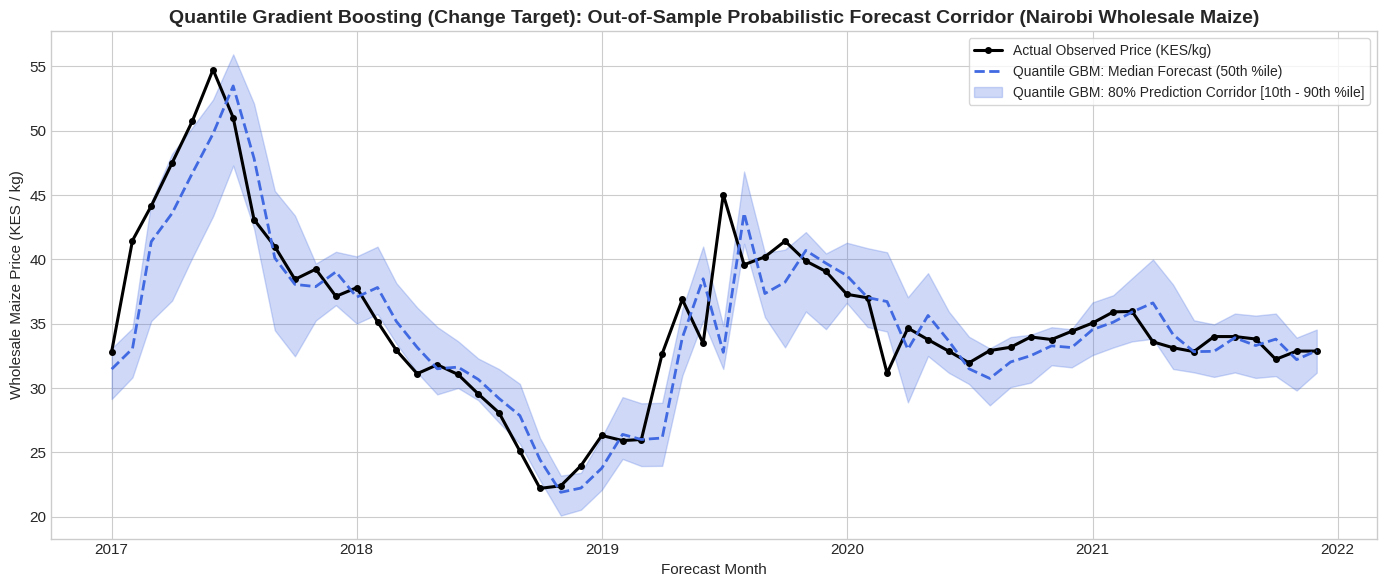

Nairobi Empirical Corridor Coverage: 70.0% (42/60 months)
Nairobi Median MAE: 2.07 KES/kg


In [14]:
# Visualizing the 80% Probabilistic Price Corridor for Nairobi (Fixed Change-Target GBM)
df_nbi_pred = pd.DataFrame(predictions_log).sort_values('date').reset_index(drop=True)

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(df_nbi_pred['date'], df_nbi_pred['actual'], label='Actual Observed Price (KES/kg)', color='black', linewidth=2.2, marker='o', markersize=4)
ax.plot(df_nbi_pred['date'], df_nbi_pred['median_50'], label='Quantile GBM: Median Forecast (50th %ile)', color='royalblue', linewidth=2, linestyle='--')
ax.fill_between(
    df_nbi_pred['date'], df_nbi_pred['low_10'], df_nbi_pred['high_90'],
    color='royalblue', alpha=0.25, label='Quantile GBM: 80% Prediction Corridor [10th - 90th %ile]'
)

ax.set_title("Quantile Gradient Boosting (Change Target): Out-of-Sample Probabilistic Forecast Corridor (Nairobi Wholesale Maize)", fontsize=14, fontweight='bold')
ax.set_xlabel("Forecast Month")
ax.set_ylabel("Wholesale Maize Price (KES / kg)")
ax.legend(loc='upper right', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

# Verification of empirical coverage in Nairobi test series
nbi_cov = np.mean((df_nbi_pred['actual'] >= df_nbi_pred['low_10']) & (df_nbi_pred['actual'] <= df_nbi_pred['high_90'])) * 100
nbi_mae = np.mean(np.abs(df_nbi_pred['actual'] - df_nbi_pred['median_50']))
print(f"Nairobi Empirical Corridor Coverage: {nbi_cov:.1f}% ({np.sum((df_nbi_pred['actual'] >= df_nbi_pred['low_10']) & (df_nbi_pred['actual'] <= df_nbi_pred['high_90']))}/60 months)")
print(f"Nairobi Median MAE: {nbi_mae:.2f} KES/kg")

---
## Section F: Validation roadmap (CAT 2 Question 4)

Instruction 4 asks for other methods that could further validate the base model, for example by building models that follow the same process and comparing them. This section describes how we would do that. We describe it here and have not run it yet.

```
       [Tier 0: Naive Persistence Baseline]
             │  (P_t = P_{t-1})
             ▼
       [Tier 1: Regularised Linear Quantile Regression (Change Target)]
             │  (L1/Lasso linear model on monthly change, with spatial features)
             ▼
       [Tier 2: Quantile Gradient Boosting Base Model (Change Target)]
             │  (Trees on the change target, using lags, rolling statistics,
             │   seasonality and neighbour features: spatial_neighbor_lag1, eldoret_lag1)
             ▼
       [Tier 3: Wider Spatial Network Model (Extension)]
             │  (More markets, multi-hop lags, trade-based weights)
             ▼
       [Stress test: Simulated Data Blackout]
             (Hide one market's recent data to see whether its neighbours can fill in)
```

*Note:* the Tier 2 base model already uses some neighbour-market information (`spatial_neighbor_lag1` and `eldoret_lag1`). Tier 3 is a future extension with more markets and trade-based weights.

---

### The simulated data blackout
Market data collection can stop for many reasons, such as broken infrastructure, bad weather or administrative changes. The blackout test checks whether neighbouring markets can make up for a market that stops reporting.
1. **Hide the data.** Pick a target market (for example Nairobi) and remove $K \in \{1, 2, 3, 6\}$ months of its recent prices.
2. **Fill in from neighbours.** Replace the missing local history with the inverse-distance weighted prices of nearby markets (for example Nakuru, Eldoret and Kisumu).
3. **Hypothesis to test.** During a blackout, using neighbour prices will give smaller errors and better-calibrated intervals than carrying the last known price forward. We have not tested this yet. It will be part of the final project notebook.

---

### Possible extension: correcting coverage
Coverage fell below the 80% target for every model (about 68.7% to 73.0%), and it was worst in the 2017 drought. One possible fix is a calibration step based on recent errors:
* Track how often the true price fell outside the interval over the last few months ($t-3$ to $t-1$).
* Widen the bounds $[q_{0.10}, q_{0.90}]$ when recent errors are larger than the model expected.

The aim is for the interval to widen on its own during sudden shifts and bring coverage back toward 80%.